# Customer Churn: Exploratory Data Analysis

**Business problem:** Losing customers is expensive. If we can understand *who* is likely to leave and *why*, the business can act before they go.

**Objective of this notebook:**
- Inspect the dataset structure, types, and summary statistics.
- Audit data quality (missing values, duplicates, categorical inconsistencies, and outliers).
- Explore univariate distributions and bivariate relationships with `Churn`.
- Summarize actionable **Key Insights & Recommendations** for both business retention and feature engineering.

## 1. Import & settings

In [19]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = "../data/raw/customer_churn.csv"

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams["figure.dpi"] = 100

## 2. Load the data

In [20]:
df = pd.read_csv(DATA_PATH)
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
df.head()

Rows: 3,941 | Columns: 11


,Tenure,WarehouseToHome,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,DaySinceLastOrder,CashbackAmount,Churn
0,15.00,29.00,4,Laptop & Accessory,3,Single,2,0,7.00,143.32,0
1,7.00,25.00,4,Mobile,1,Married,2,0,7.00,129.29,0
2,27.00,13.00,3,Laptop & Accessory,1,Married,5,0,7.00,168.54,0
3,20.00,25.00,4,Fashion,3,Divorced,7,0,NaN,230.27,0
4,30.00,15.00,4,Others,4,Single,8,0,8.00,322.17,0


### 2.1 Target definition & schema inspection

In [21]:
TARGET = "Churn"

In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3941 entries, 0 to 3940
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Tenure                    3747 non-null   float64
 1   WarehouseToHome           3772 non-null   float64
 2   NumberOfDeviceRegistered  3941 non-null   int64  
 3   PreferedOrderCat          3941 non-null   object 
 4   SatisfactionScore         3941 non-null   int64  
 5   MaritalStatus             3941 non-null   object 
 6   NumberOfAddress           3941 non-null   int64  
 7   Complain                  3941 non-null   int64  
 8   DaySinceLastOrder         3728 non-null   float64
 9   CashbackAmount            3941 non-null   float64
 10  Churn                     3941 non-null   int64  
dtypes: float64(4), int64(5), object(2)
memory usage: 338.8+ KB


### 2.2 Descriptive statistics

In [23]:
df.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
Tenure,"3,747.00",10.08,8.50,0.00,2.00,9.00,16.00,61.00
WarehouseToHome,"3,772.00",15.65,8.45,5.00,9.00,14.00,21.00,127.00
NumberOfDeviceRegistered,"3,941.00",3.68,1.01,1.00,3.00,4.00,4.00,6.00
SatisfactionScore,"3,941.00",3.09,1.38,1.00,2.00,3.00,4.00,5.00
NumberOfAddress,"3,941.00",4.24,2.63,1.00,2.00,3.00,6.00,22.00
Complain,"3,941.00",0.28,0.45,0.00,0.00,0.00,1.00,1.00
DaySinceLastOrder,"3,728.00",4.53,3.67,0.00,2.00,3.00,7.00,46.00
CashbackAmount,"3,941.00",176.71,48.79,0.00,145.70,163.34,195.25,324.99
Churn,"3,941.00",0.17,0.38,0.00,0.00,0.00,0.00,1.00


## 3. Data quality

In [24]:
missing = (df.isnull().sum().to_frame("missing_count").sort_values(by="missing_count", ascending=False))
missing[missing["missing_count"] > 0]

,missing_count
DaySinceLastOrder,213
Tenure,194
WarehouseToHome,169


In [25]:
cols_with_na = missing.index[missing["missing_count"] > 0].tolist()

rows = []
for c in cols_with_na:
     rate = df.groupby(df[c].isna())[TARGET].mean().mul(100)
     rows.append({
          "column": c,
          "churn_% when present": rate.get(False, np.nan),
          "churn_% when missing": rate.get(True, np.nan),
     })

pd.DataFrame(rows)

,column,churn_% when present,churn_% when missing
0,DaySinceLastOrder,17.01,18.78
1,Tenure,16.28,32.99
2,WarehouseToHome,16.28,35.50


### 3.2 Duplicate rows

In [26]:
dup = df.duplicated().sum()
print(f"Duplicate rows: {dup:,} ({dup / df.shape[0]:.2%})")

Duplicate rows: 671 (17.03%)


### 3.3 Categorical consistency

In [27]:
cat_cols = ["PreferedOrderCat", "MaritalStatus"]
for c in cat_cols:
     print(df[c].value_counts(dropna=False), "\n")

PreferedOrderCat
Laptop & Accessory    1458
Mobile Phone           887
Fashion                585
Mobile                 559
Grocery                273
Others                 179
Name: count, dtype: int64 

MaritalStatus
Married     2055
Single      1310
Divorced     576
Name: count, dtype: int64 



### 3.4 Outliers

In [28]:
num_cols = ["Tenure", "WarehouseToHome", "DaySinceLastOrder", "CashbackAmount"]
discrete_cols = ["NumberOfDeviceRegistered", "NumberOfAddress", "SatisfactionScore", "Complain"]

def iqr_outliers(s):
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

pd.DataFrame({
    "outliers": {c: iqr_outliers(df[c]) for c in num_cols + discrete_cols},
}).assign(pct=lambda d: d["outliers"] / len(df) * 100)

,outliers,pct
Tenure,4,0.10
WarehouseToHome,1,0.03
DaySinceLastOrder,43,1.09
CashbackAmount,316,8.02
NumberOfDeviceRegistered,271,6.88
NumberOfAddress,3,0.08
SatisfactionScore,0,0.00
Complain,0,0.00


## 4. The target: `Churn`

Churn
0    3267
1     674
Name: count, dtype: int64
Churn rate: 17.1%


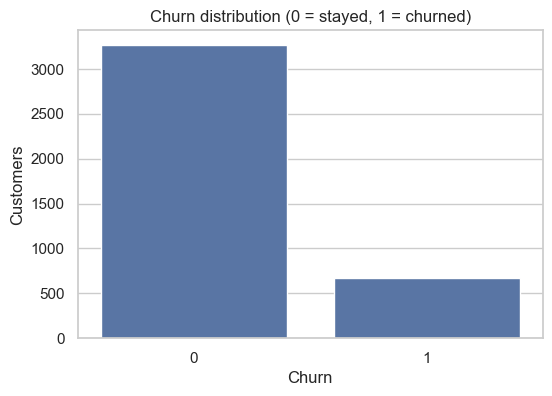

In [29]:
counts = df[TARGET].value_counts()
rate = df[TARGET].mean()
print(f"{counts}")
print(f"Churn rate: {rate:.1%}")

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=counts.index, y=counts.values, ax=ax)
ax.set(title="Churn distribution (0 = stayed, 1 = churned)", xlabel="Churn", ylabel="Customers")
plt.show()


## 5. Single-variable analysis

### 5.1 Numeric columns

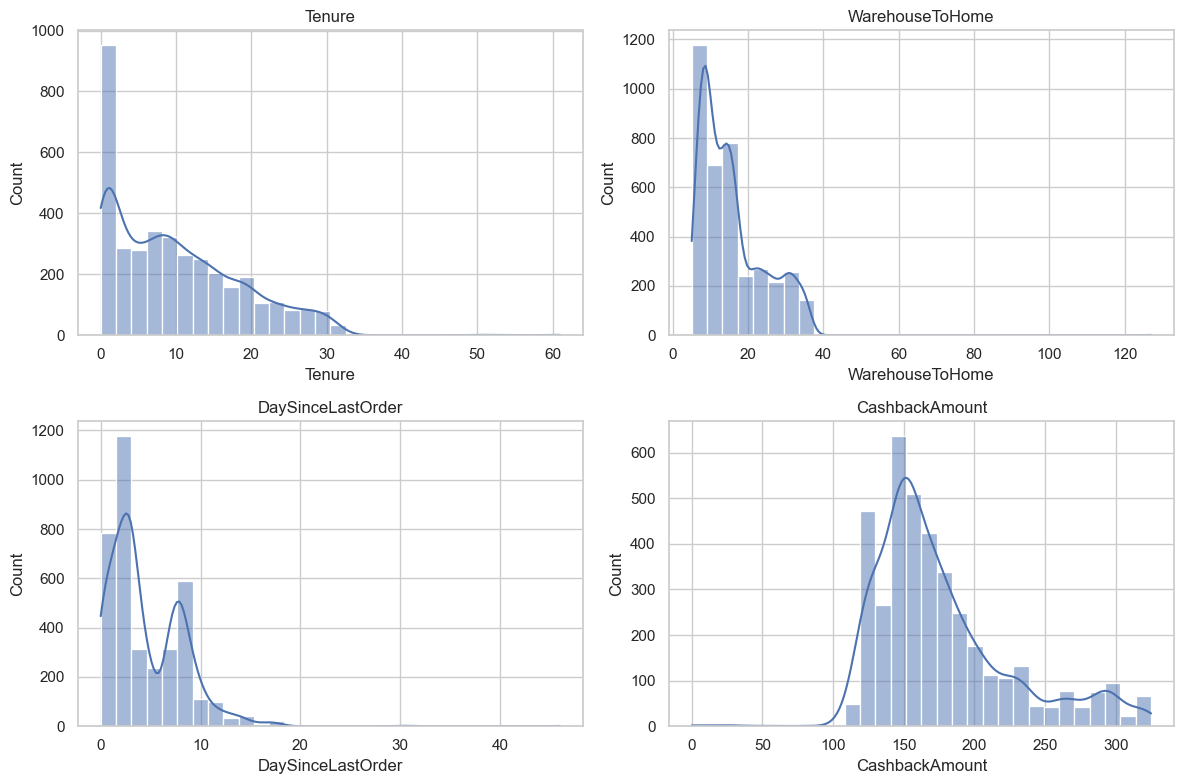

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(df[c].dropna(), bins=30, kde=True, ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.show()

### 5.2 Discrete and categorical columns

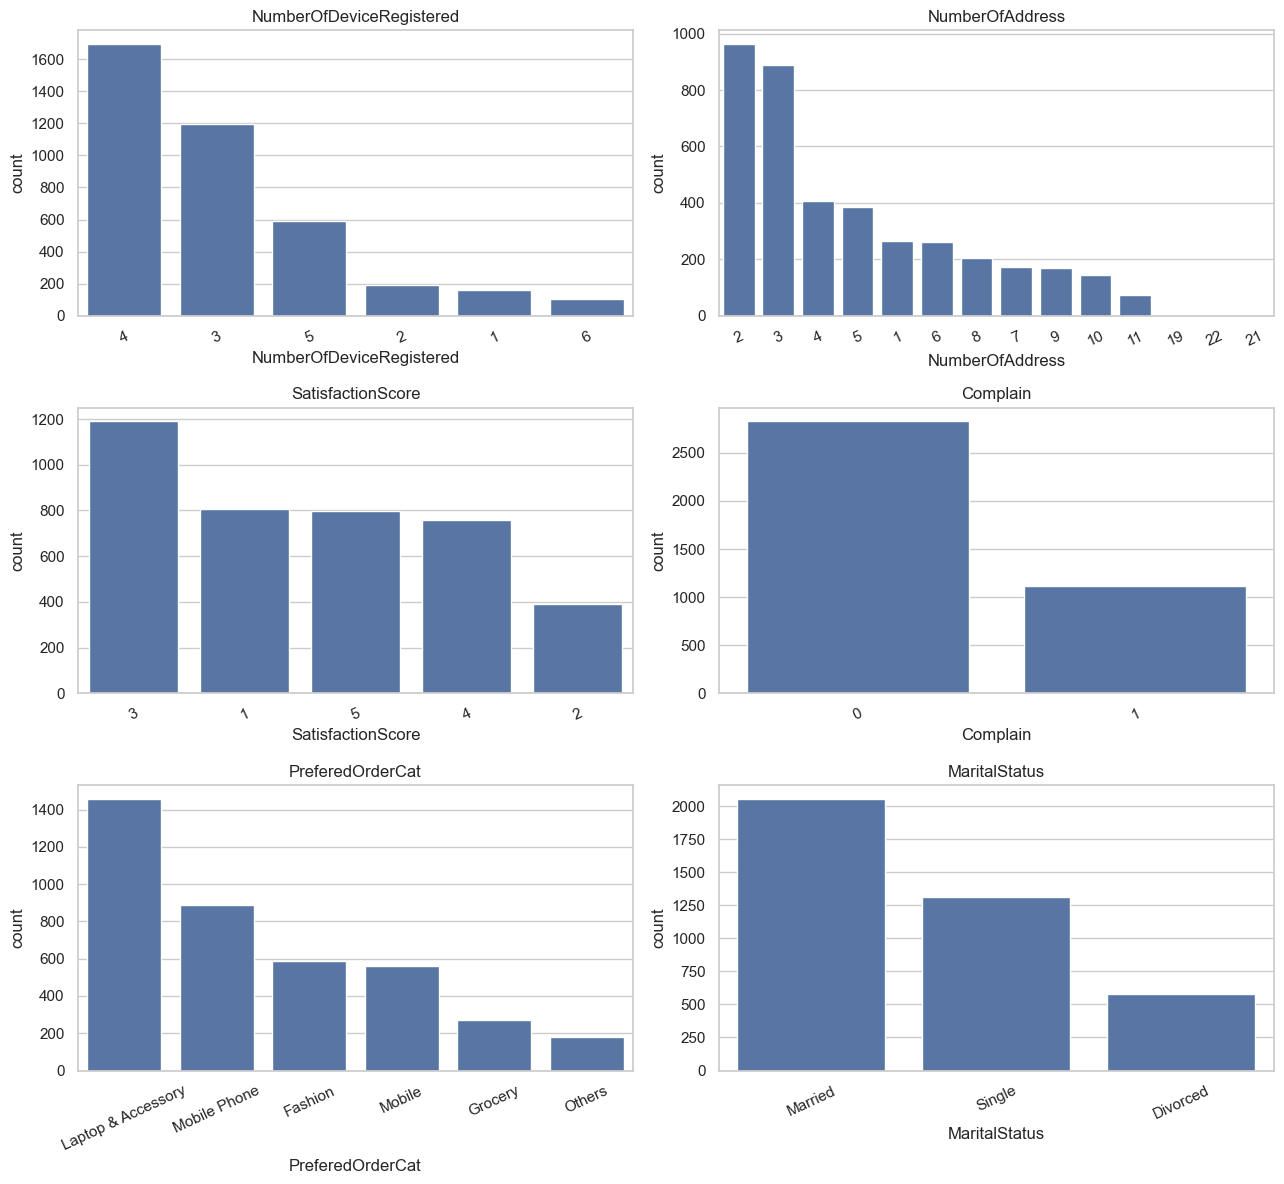

In [31]:
cat_like = discrete_cols + ["PreferedOrderCat", "MaritalStatus"]

fig, axes = plt.subplots(3, 2, figsize=(13, 12))
for ax, c in zip(axes.ravel(), cat_like):
    order = df[c].value_counts().index
    sns.countplot(data=df, x=c, order=order, ax=ax)
    ax.set_title(c)
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

## 6. Each feature vs churn

### 6.1 Numeric feature vs churn

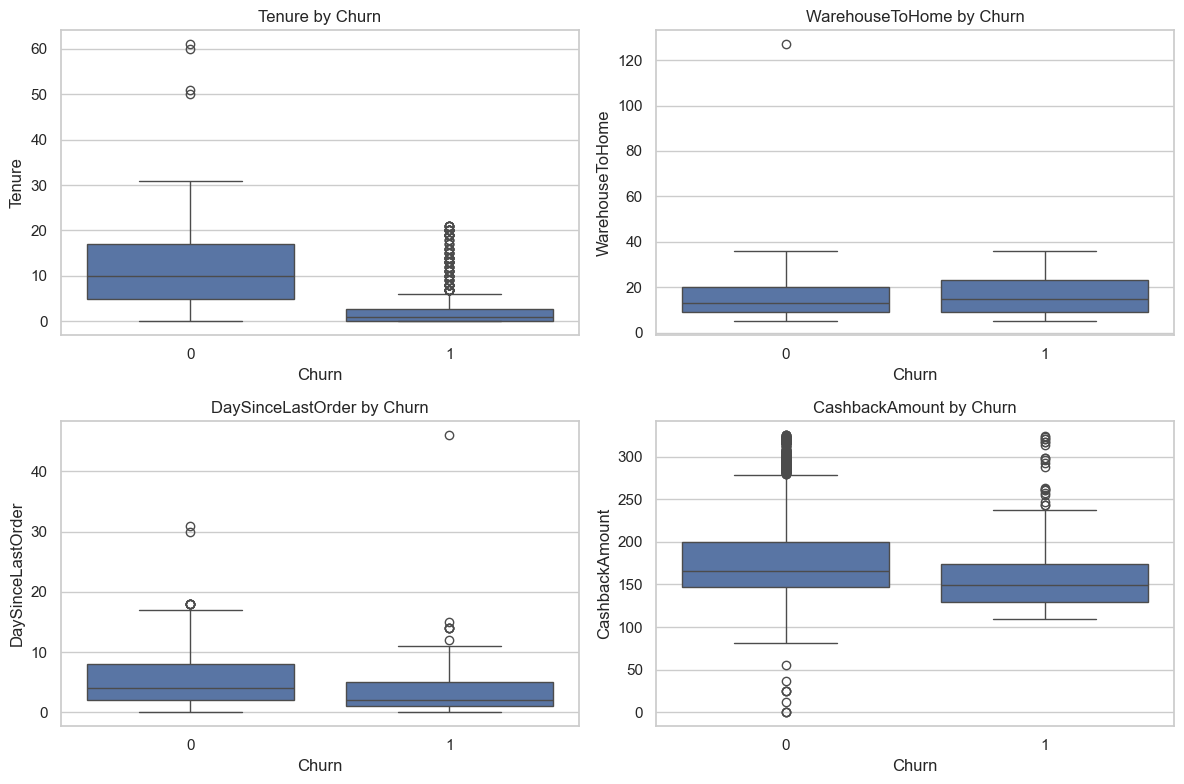

Churn,stayed (median),churned (median)
Tenure,10.00,1.00
WarehouseToHome,13.00,15.00
DaySinceLastOrder,4.00,2.00
CashbackAmount,166.08,149.34


In [32]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(data=df, x=TARGET, y=c, ax=ax)
    ax.set_title(f"{c} by Churn")
plt.tight_layout()
plt.show()

df.groupby(TARGET)[num_cols].median().T.rename(columns={0: "stayed (median)", 1: "churned (median)"})

### 6.2 Churn rate by category

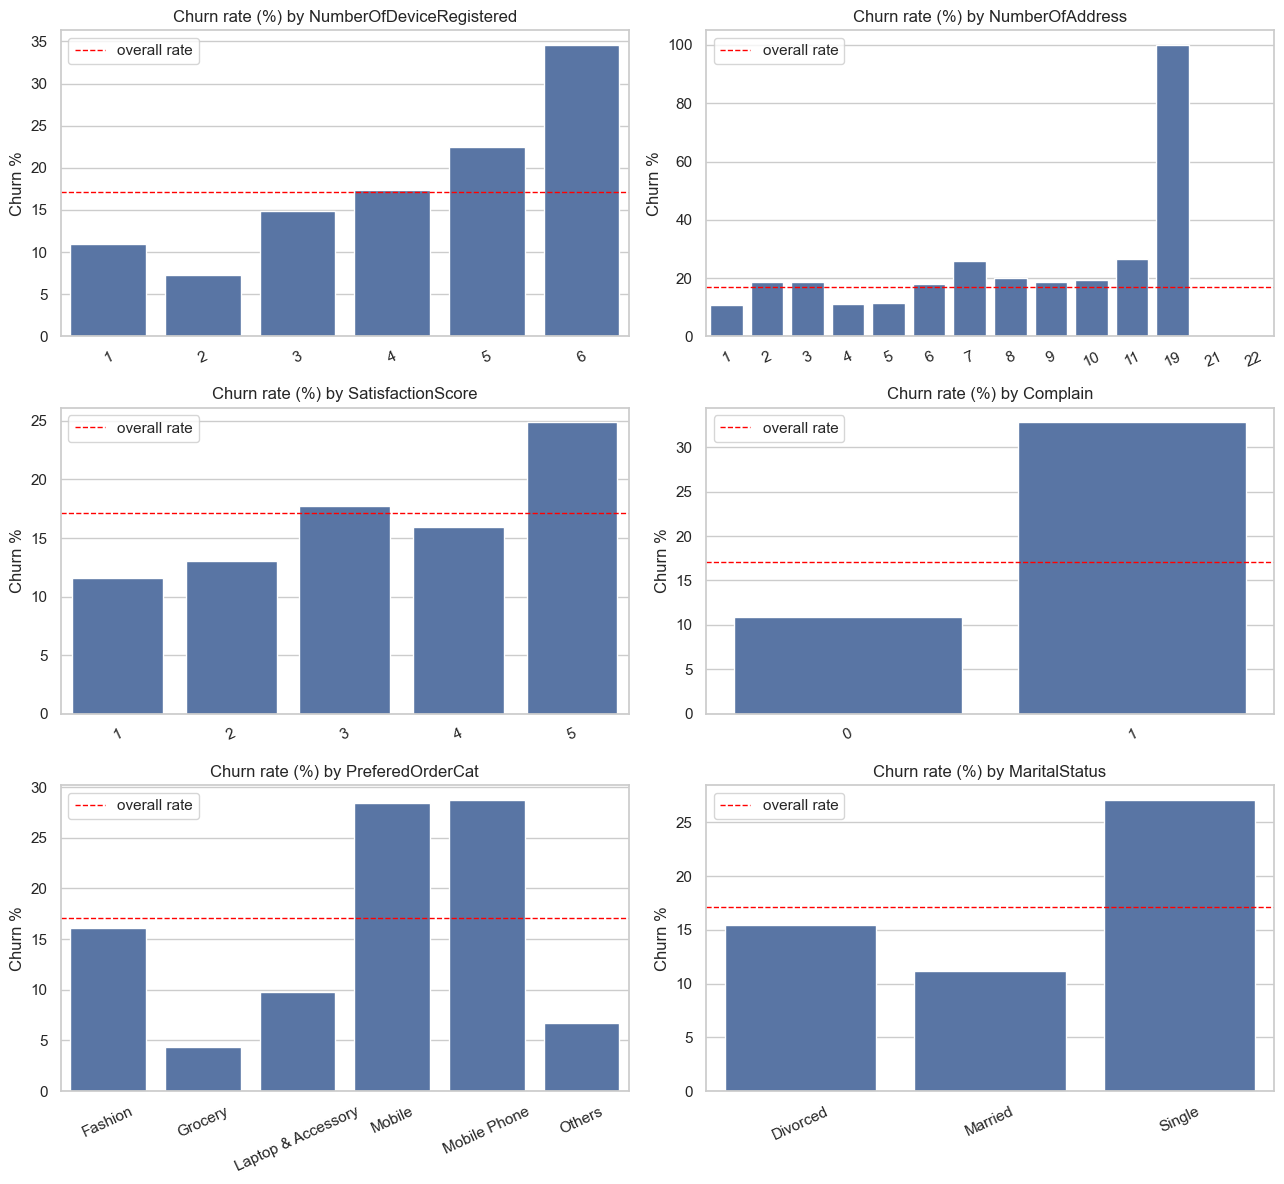

In [33]:
def churn_rate_by(col, ax, order=None):
    rate = df.groupby(col)[TARGET].mean().mul(100)
    if order is not None:
        rate = rate.reindex(order)
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax)
    ax.axhline(df[TARGET].mean() * 100, color="red", ls="--", lw=1, label="overall rate")
    ax.set(title=f"Churn rate (%) by {col}", xlabel="", ylabel="Churn %")
    ax.tick_params(axis="x", rotation=25)
    ax.legend()

fig, axes = plt.subplots(3, 2, figsize=(13, 12))
for ax, c in zip(axes.ravel(), cat_like):
    churn_rate_by(c, ax)
plt.tight_layout()
plt.show()

### 6.3 Churn rate by tenure band

,customers,churn_rate
Tenure,,
0-3 mo,1089,43.16
4-6 mo,430,6.98
7-12 mo,927,5.29
13-24 mo,1018,5.99
25+ mo,283,0.00


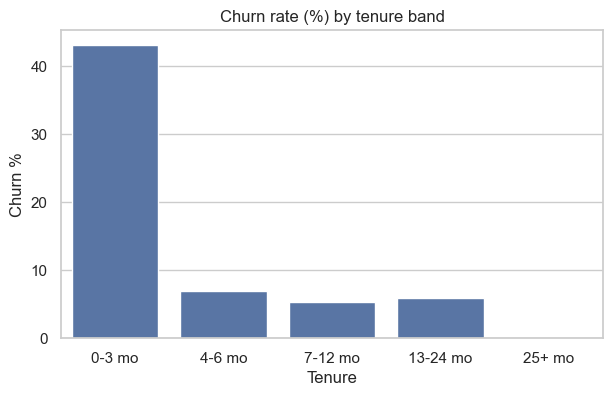

In [34]:
bins = [-1, 3, 6, 12, 24, np.inf]
labels = ["0-3 mo", "4-6 mo", "7-12 mo", "13-24 mo", "25+ mo"]
tenure_band = pd.cut(df["Tenure"], bins=bins, labels=labels)

band = (
    df.groupby(tenure_band, observed=True)[TARGET]
      .agg(customers="count", churn_rate="mean")
      .assign(churn_rate=lambda d: d["churn_rate"] * 100)
)
display(band)

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=band.index.astype(str), y=band["churn_rate"], ax=ax)
ax.set(title="Churn rate (%) by tenure band", xlabel="Tenure", ylabel="Churn %")
plt.show()

## 7 Correlation

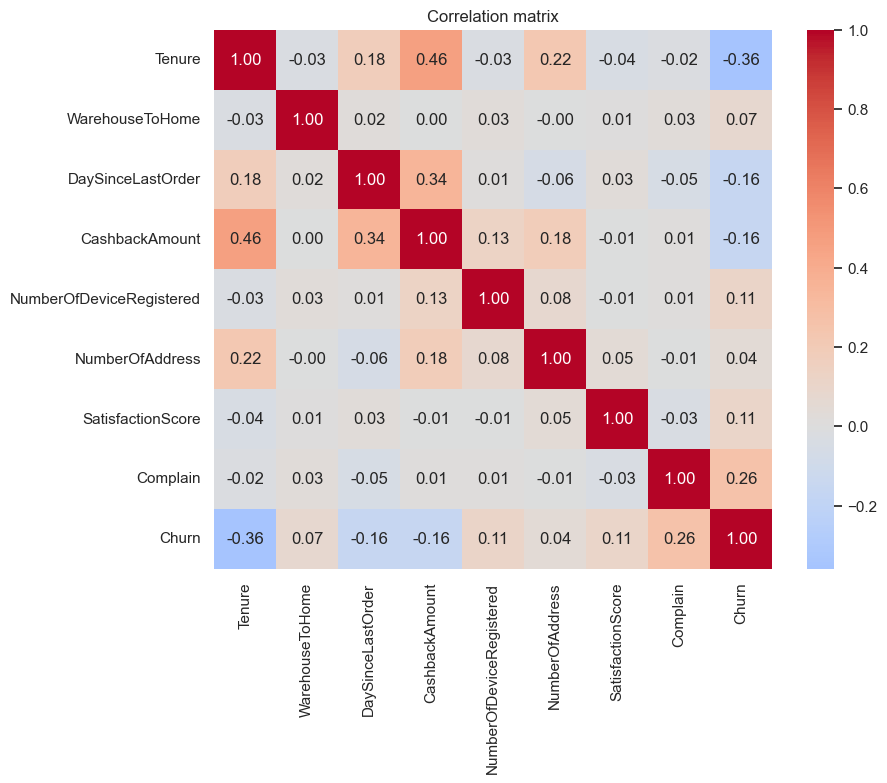

In [35]:
corr_cols = num_cols + ["NumberOfDeviceRegistered", "NumberOfAddress", "SatisfactionScore", "Complain", TARGET]
corr = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation matrix")
plt.show()

## 8. Key Insights & Recommendations